# Sensibilidad directa e identificabilidad

**Pregunta:** ¿Qué diferencias entre optimizadores sobreviven a una comparación con datos idénticos?

**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** niveles 1–2 y fundamentos de inversión; 35 min.



## Objetivos

Pregunta: ¿Qué ventanas de frecuencia resuelven localmente el modelo de espesores fijos y Adam alcanza la solución sintética de la ruta trust-region?



## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` es requerido por el operador directo MT.



## Datos

El experimento de optimizadores usa 60 frecuencias entre 0.001–100 Hz, espesores fijos de 300 m y 700 m, verdad de tres capas de 80/12/250 Ω·m y una máscara congelada. Un control separado de 24 frecuencias prueba rango local por banda. Clear Lake cl061 queda fuera de ambos ajustes porque falla su filtro 1D medido.


## Método

El operador estratificado del repositorio usa respuesta de semiespacio `Z=√(iωμ₀ρ)` y la propaga recursivamente por capas finitas usando `k=√(iωμ₀/ρ)`, `w=√(iωμ₀ρ)` y `t=tanh(kh)`. La base es infinita; la geometría es 1D, isótropa y cuasiestática. Use las funciones existentes `electromagnetics.impedance` y `curves`, sin reimplementarlas. Compare la verdad sintética exacta con un ajuste guardado sobre las frecuencias versionadas, graficando resistividad aparente (Ω·m) y fase (grados) frente al período (s). Curvas parecidas no prueban unicidad de resistividad o espesor: dimensionalidad, static shift, errores correlacionados y espesor fijo quedan fuera de la calibración.

Los parámetros son log-resistividades: positivos por construcción y pasos iguales son cambios multiplicativos iguales. Residuos complejos usan sigma por componente real; ambas partes aportan al ajuste. Frecuencias no son muestras independientes de profundidad: kernels se solapan y un período no identifica una interfaz. Sensibilidad local y cobertura dependen de parametrización fija y no descartan equivalencia global.



## Comparación

La comparación distingue los métodos publicados, el código del producto y la evidencia versionada. Una afirmación de avance requiere dominios retenidos independientes, incertidumbre calibrada y réplica.



In [1]:
from pathlib import Path
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "matplotlib", "scipy"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Llame al operador directo de tierra estratificada del repositorio para su objetivo de calibración sintético.
import json, sys
from pathlib import Path

sys.path.insert(0, str(root / "data-pipeline"))
import electromagnetics as em
from electromagnetics import impedance, curves

cal = json.loads((root / "data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8"))
f = cal["frequencies_hz"]
rho = cal["calibration_model"]
h = cal["fixed_thickness_m"]
z = impedance(rho, h, f)
truth = curves(z, f)
print("rho sintética Ω·m", rho, "espesor fijo (m)", h, "número de frecuencias", len(f))


Versiones del entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
rho sintética Ω·m [180.0, 20.0] espesor fijo (m) [450.0] número de frecuencias 24


### Intercambio de conductancia con espesor fijo

Espesor y resistividad cambian juntos; el residual de impedancia blanqueado mide cómo estas frecuencias distinguen la perturbación.

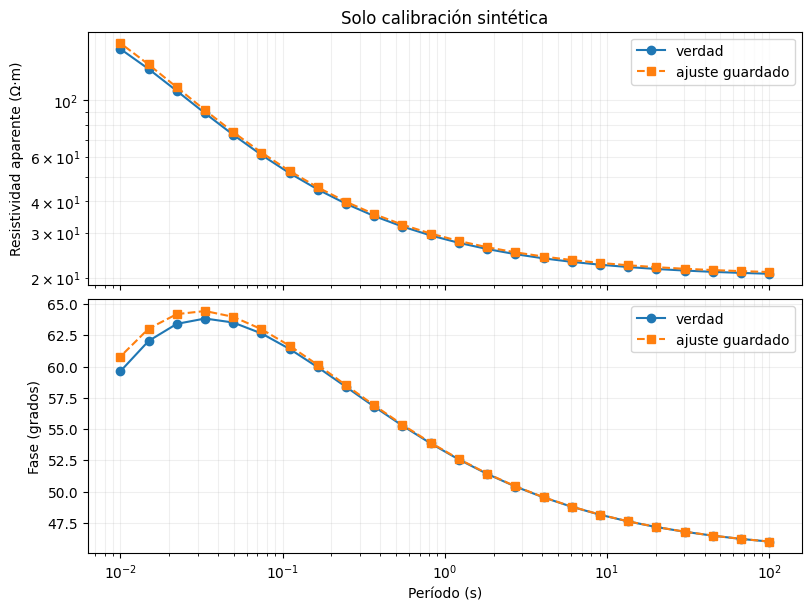

rho ajustada guardada Ω·m [198.92475596650235, 20.323660137129647]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Proyecte hacia adelante un modelo ajustado guardado y compare las curvas de respuesta física.
import matplotlib.pyplot as plt

fit = cal["rows"][0]['model']
other = curves(impedance(fit, h, f), f)
T = 1 / np.asarray(f)
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True, constrained_layout=True)
ax[0].loglog(T, truth["apparent"], "o-", label="verdad")
ax[0].loglog(T, other["apparent"], "s--", label="ajuste guardado")
ax[1].semilogx(T, truth["phase"], "o-", label="verdad")
ax[1].semilogx(T, other["phase"], "s--", label="ajuste guardado")
ax[0].set_ylabel("Resistividad aparente (Ω·m)")
ax[1].set_ylabel("Fase (grados)")
ax[1].set_xlabel("Período (s)")
[a.grid(True, which="both", alpha=0.2) or a.legend() for a in ax]
ax[0].set_title("Solo calibración sintética")
plt.show()
print("rho ajustada guardada Ω·m", fit)


### Experimento sintético: cobertura de frecuencias, ruido y equivalencia de espesor

Este experimento directo adicional **sintético** se separa del registro medido `cl061`. El operador estratificado del repositorio genera una respuesta exacta de tres capas. Su rutina implementada `identifiability` linealiza respecto de log-resistividad con ambos espesores fijos. Compare la banda completa con subconjuntos solo de bajas y altas frecuencias usando el mismo modelo y la misma incertidumbre por componente. Los valores singulares y la SD local de log-resistividad son diagnósticos condicionales de sensibilidad, no incertidumbre posterior ni prueba de unicidad.

Una segunda perturbación directa aumenta conjuntamente el espesor y la resistividad de la capa conductora finita, preservando aproximadamente su conductancia (`h/ρ`). Compare el cambio de respuesta compleja con la escala de ruido declarada. Esta equivalencia conocida es aproximada para una respuesta estratificada de frecuencia finita. Muestra el supuesto de espesor fijo; no es una segunda inversión, una afirmación de geología recuperada ni evidencia sobre `cl061`.

In [3]:
# Experimento solo sintético: sensibilidad local con espesor fijo y ventanas de frecuencia.
f_syn = np.logspace(-3, 2, 60)
active_syn = np.arange(len(f_syn)) % 4 != 1
h_syn = np.array([300.0, 700.0])
rho_syn = np.array([80.0, 12.0, 250.0])
z_syn = impedance(rho_syn, h_syn, f_syn)
sigma_syn = np.maximum(0.03 * np.abs(z_syn), 1e-12)  # SD de cada componente real e imaginaria independiente
bands = {
    "banda completa 0.001–100 Hz": np.ones(len(f_syn), dtype=bool),
    "baja frecuencia ≤0.1 Hz": f_syn <= 0.1,
    "alta frecuencia ≥1 Hz": f_syn >= 1.0,
}


### Evaluar sensibilidad por ventana de frecuencia

La identificabilidad usa un modelo de espesores fijos y sus incertidumbres por componente. El barrido contrasta rango local y sensibilidad paramétrica en subconjuntos completo, bajo y alto.

In [4]:
# Calcula rango local y sensibilidad para cada máscara de frecuencia.
diags = {}
for label, mask in bands.items():
    d = em.identifiability(rho_syn, h_syn, f_syn, sigma_syn, mask)
    diags[label] = d
    print(
        label,
        "N=",
        int(mask.sum()),
        "rango efectivo=",
        d["effective_rank"],
        "/",
        d["parameter_count"],
        "valores singulares=",
        np.round(d["singular_values"], 3),
        "SD local de log-rho=",
        np.round(d["local_logrho_sd"], 3),
        "capas no resueltas=",
        d["unresolved_layers"],
        "estado=",
        d["status"],
    )


banda completa 0.001–100 Hz N= 60 rango efectivo= 3 / 3 valores singulares= [107.981  61.827  27.976] SD local de log-rho= [0.036 0.011 0.015] capas no resueltas= [] estado= locally_resolved
baja frecuencia ≤0.1 Hz N= 24 rango efectivo= 2 / 3 valores singulares= [71.098 31.793  0.1  ] SD local de log-rho= [9.974 0.668 0.022] capas no resueltas= [0] estado= unresolved
alta frecuencia ≥1 Hz N= 24 rango efectivo= 3 / 3 valores singulares= [64.944 27.966  6.79 ] SD local de log-rho= [0.036 0.017 0.147] capas no resueltas= [] estado= locally_resolved


### Probar el intercambio de conductancia de capa finita

El barrido de sensibilidad informa el rango del Jacobiano y la incertidumbre local para cada ventana de frecuencia. Este cálculo directo separado perturba conjuntamente el espesor y la resistividad de la capa finita, y mide la discrepancia de impedancia blanqueada por ruido.

In [5]:
# Perturbación directa h/rho de la capa conductora finita.
rho_trade = np.array([rho_syn[0], rho_syn[1] * 1.15, rho_syn[2]])
h_trade = np.array([h_syn[0], h_syn[1] * 1.15])
z_trade = impedance(rho_trade, h_trade, f_syn)
whitened = np.abs(z_trade - z_syn) / sigma_syn
trade_wrms = float(np.sqrt(np.mean(whitened**2) / 2))
print("Equivalencia sintética de conductancia; h base m=", h_syn, "rho ohm m=", rho_syn)
print("h perturbado m=", h_trade, "rho ohm m=", rho_trade, "; WRMS por componente blanqueado=", trade_wrms)


Equivalencia sintética de conductancia; h base m= [300. 700.] rho ohm m= [ 80.  12. 250.]
h perturbado m= [300. 805.] rho ohm m= [ 80.   13.8 250. ] ; WRMS por componente blanqueado= 0.5429574698818997


Ejecute región de confianza acotada sobre respuesta sintética recién calculada.

In [6]:
# Ejecute región de confianza acotada sobre respuesta sintética recién calculada.
active_syn = np.arange(len(f_syn)) % 4 != 1
fit_lm = em.invert_mt(
    h_syn, f_syn, z_syn, sigma_syn, active=active_syn, initial=rho_syn * 1.2, methods=("mt-lm",), max_nfev=120
)["mt-lm"]
print("Modelo LM Ω·m:", np.round(fit_lm['model'], 3), "WRMS:", fit_lm["metrics"]["active_component_wrms"])


Modelo LM Ω·m: [ 79.987  12.001 249.984] WRMS: 0.0006162534002809828


Ejecute el método CPU alternativo con los mismos datos y modelo inicial.

In [7]:
import os
# Ejecute el optimizador del producto basado en Torch en el entorno aislado del pipeline.
import json, os, subprocess
from pathlib import Path

work = Path(os.environ["CAOS_TEMP_ROOT"]) / "caos-geophysics-mt-notebook"
work.mkdir(parents=True, exist_ok=True)
input_path = work / "mt-adam-input.json"
output_path = work / "mt-adam-output.json"
request = {
    "h": h_syn.tolist(),
    "f": f_syn.tolist(),
    "rho": rho_syn.tolist(),
    "sigma": sigma_syn.tolist(),
    "active": active_syn.tolist(),
    "z_real": z_syn.real.tolist(),
    "z_imag": z_syn.imag.tolist(),
    "initial": (rho_syn * 1.2).tolist(),
}
input_path.write_text(json.dumps(request), encoding="utf-8")
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-pipeline" / "Scripts" / "python.exe"
if not engine.is_file():
    raise RuntimeError("The isolated pipeline environment is required for Torch-backed mt-adam.")


### Preparar la solicitud del optimizador aislado

La solicitud se escribe bajo la raíz temporal configurada y se comprueba el intérprete dedicado del pipeline antes de ensamblar el proceso hijo. No se sustituye el método Torch por una aproximación local del notebook.

In [8]:
# Preparar la solicitud del optimizador aislado.
child = "\n".join(
    [
        "import json, sys",
        "from pathlib import Path",
        "import numpy as np",
        "sys.path.insert(0, str(Path(sys.argv[1]) / 'data-pipeline'))",
        "import electromagnetics as em",
        "source = json.loads(Path(sys.argv[2]).read_text(encoding='utf-8'))",
        "z = np.asarray(source['z_real']) + 1j * np.asarray(source['z_imag'])",
        "fit = em.invert_mt(",
    "    source['h'], source['f'], z, source['sigma'],",
    "    active=source['active'], initial=source['initial'],",
    "    methods=('mt-adam',), adam_steps=1200,",
    ")['mt-adam']",
        "answer = {",
    "    'model': np.asarray(fit['model']).tolist(),",
    "    'active_wrms': float(fit['metrics']['active_component_wrms']),",
    "    'heldout_wrms': float(fit['metrics']['withheld_component_wrms']),",
    "}",
        "Path(sys.argv[3]).write_text(json.dumps(answer), encoding='utf-8')",
    ]
)


### Ejecutar el método Adam del producto

Este programa hijo importa la implementación del repositorio en el entorno aislado, llama `invert_mt` con `mt-adam` y serializa el modelo recuperado junto con métricas activas y reservadas para este kernel.

In [9]:
# Ejecutar el método Adam del producto.
completed = subprocess.run(
    [str(engine), "-c", child, str(root), str(input_path), str(output_path)],
    cwd=root,
    capture_output=True,
    text=True,
    timeout=300,
)
if completed.returncode:
    raise RuntimeError(completed.stderr[-3000:])
adam_result = json.loads(output_path.read_text(encoding="utf-8"))
print(
    "Modelo Adam Ω·m:",
    np.round(adam_result['model'], 3),
    "WRMS de ajuste:",
    adam_result["active_wrms"],
    "WRMS retenido:",
    adam_result["heldout_wrms"],
)


Modelo Adam Ω·m: [ 79.987  12.001 249.984] WRMS de ajuste: 0.0006162534252895064 WRMS retenido: 0.0005956383478404238


### Graficar sensibilidad y compromiso

Esta celda representa los rangos de sensibilidad y el compromiso paramétrico calculados arriba; no ajusta ni evalúa datos de campo.


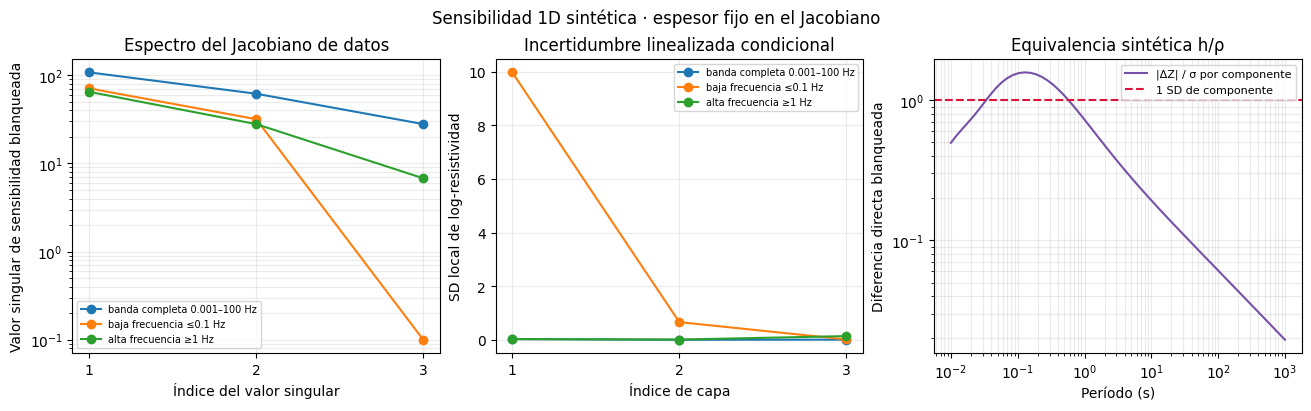

In [10]:
# Ejecute el experimento documentado con la evidencia del repositorio.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for label, d in diags.items():
    s = np.asarray(d["singular_values"], float)
    ax[0].semilogy(np.arange(1, len(s) + 1), s, marker="o", label=label)
    ax[1].plot(np.arange(1, len(rho_syn) + 1), d["local_logrho_sd"], marker="o", label=label)
ax[0].set_xlabel("Índice del valor singular")
ax[0].set_ylabel("Valor singular de sensibilidad blanqueada")
ax[0].set_title("Espectro del Jacobiano de datos")
ax[1].set_xlabel("Índice de capa")
ax[1].set_ylabel("SD local de log-resistividad")
ax[1].set_title("Incertidumbre linealizada condicional")
for a in ax[:2]:
    a.set_xticks(np.arange(1, 4))
    a.grid(True, which="both", alpha=0.25)
    a.legend(fontsize=7)
T = 1 / f_syn
ax[2].loglog(T, whitened, label="|ΔZ| / σ por componente", color="#7651a8")
ax[2].axhline(1, color="crimson", ls="--", label="1 SD de componente")
ax[2].set_xlabel("Período (s)")
ax[2].set_ylabel("Diferencia directa blanqueada")
ax[2].set_title("Equivalencia sintética h/ρ")
ax[2].grid(True, which="both", alpha=0.25)
ax[2].legend(fontsize=8)
fig.suptitle("Sensibilidad 1D sintética · espesor fijo en el Jacobiano")
plt.show()


### Procedencia de datos

Clear Lake cl061 tiene 42 períodos medidos y falla el filtro tensorial 1D necesario; se conserva solo para QC. La comparación de optimizadores usa impedancias sintéticas con semilla y verdad de capas conocida. No se mezclan valores EDI medidos en ese experimento.


## Resultados

El Jacobiano de bajas frecuencias tiene rango 2/3 y SD local de log-resistividad 9.974 en la capa superior; las bandas completa y alta tienen rango 3/3. LM y Adam recuperan aproximadamente [79.987, 12.001, 249.984] Ω·m, con WRMS activo de 0.000616 en ambos.
### Entradas congeladas del optimizador



**Respuesta:** El Jacobiano de bajas frecuencias tiene rango 2/3 y SD local de log-resistividad 9.974 en la capa superior; las bandas completa y alta tienen rango 3/3. LM y Adam recuperan aproximadamente [79.987, 12.001, 249.984] Ω·m, con WRMS activo de 0.000616 en ambos.

LM y Adam comparten vector de impedancia y reserva sintéticos; el barrido de identificabilidad solo cambia la banda de frecuencias.


## Resumen

El subconjunto de baja frecuencia deja una capa localmente no resuelta aunque la banda completa no. El acuerdo LM/Adam valida dos implementaciones sobre este objetivo sintético; no establece unicidad global, ruido realista, dimensionalidad ni transferencia a terreno.



## Referencias

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)